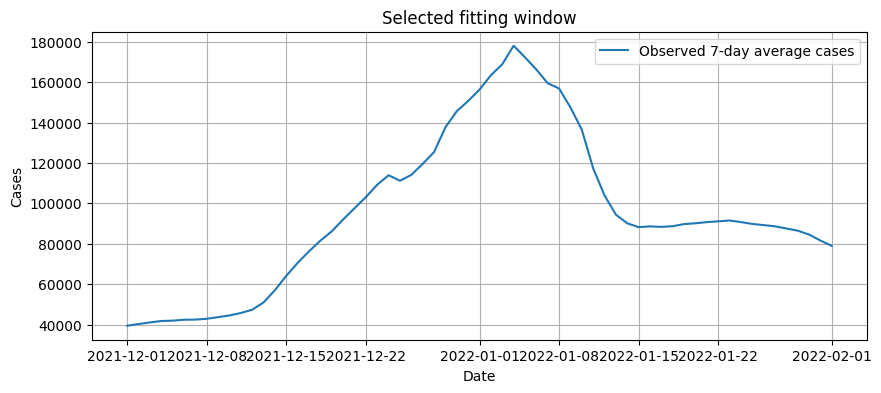

        date      cases_7d
0 2021-12-01  39422.714286
1 2021-12-02  40265.857143
2 2021-12-03  41059.571429
3 2021-12-04  41762.571429
4 2021-12-05  41931.142857
Length: 63


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

data = df_fit["cases_7d"].values
dates = df_fit["date"].values
t = np.arange(len(data))

# population
N = 67_000_000

# initial values
I0 = float(data[0])
R0 = 0.0
S0 = N - I0 - R0

plt.figure(figsize=(10, 4))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases")
plt.title("Selected fitting window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

print(df_fit[["date", "cases_7d"]].head())
print("Length:", len(df_fit))

In [4]:
def get_segment_indices(t_eval, break_indices):
    # break_indices example: [12, 57]
    # segments: [0,12), [12,57), [57,T)
    bounds = [0] + break_indices + [len(t_eval)]
    segments = []
    for i in range(len(bounds) - 1):
        segments.append((bounds[i], bounds[i+1]))
    return segments

def beta_piecewise_exp(tt, break_indices, beta_base, lambdas):
    # determine which segment tt belongs to
    bounds = [0] + break_indices + [10**9]
    for k in range(len(beta_base)):
        if bounds[k] <= tt < bounds[k+1]:
            local_t = tt - bounds[k]
            return beta_base[k] * np.exp(-lambdas[k] * local_t)
    return beta_base[-1]

def sir_model_piecewise_exp(t_now, y, break_indices, beta_base, lambdas, gamma, N):
    S, I, R = y
    beta_t = beta_piecewise_exp(t_now, break_indices, beta_base, lambdas)

    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_piecewise_exp(break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t_eval):
    sol = solve_ivp(
        fun=lambda t_now, y: sir_model_piecewise_exp(t_now, y, break_indices, beta_base, lambdas, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45"
    )

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]

    beta_path = np.array([beta_piecewise_exp(tt, break_indices, beta_base, lambdas) for tt in t_eval])

    return S, I, R, beta_path

def fit_model_for_break_dates(break_dates, model_name="model"):
    # convert dates to indices
    break_indices = []
    for d in break_dates:
        idx = np.where(df_fit["date"] == pd.Timestamp(d))[0]
        if len(idx) == 0:
            raise ValueError(f"Breakpoint {d} not found in df_fit.")
        break_indices.append(int(idx[0]))

    n_seg = len(break_indices) + 1

    # params = beta_base[0..n_seg-1], lambdas[0..n_seg-1], gamma
    def loss_fn(params):
        beta_base = params[:n_seg]
        lambdas = params[n_seg:2*n_seg]
        gamma = params[-1]

        if np.any(np.array(beta_base) <= 0) or np.any(np.array(lambdas) < 0) or gamma <= 0:
            return 1e20

        S_fit, I_fit, R_fit, beta_path = simulate_piecewise_exp(
            break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t
        )

        if len(I_fit) != len(data) or np.any(np.isnan(I_fit)) or np.any(np.isinf(I_fit)):
            return 1e20

        return np.mean((I_fit - data) ** 2)

    x0 = [0.08] * n_seg + [0.01] * n_seg + [0.05]
    bounds = [(1e-6, 1.0)] * n_seg + [(0.0, 0.2)] * n_seg + [(1e-6, 1.0)]

    result = minimize(
        loss_fn,
        x0=x0,
        bounds=bounds,
        method="L-BFGS-B"
    )

    best_params = result.x
    beta_base = best_params[:n_seg]
    lambdas = best_params[n_seg:2*n_seg]
    gamma = best_params[-1]

    S_fit, I_fit, R_fit, beta_path = simulate_piecewise_exp(
        break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t
    )

    mse = np.mean((I_fit - data) ** 2)
    rmse = np.sqrt(mse)

    return {
        "model": model_name,
        "break_dates": break_dates,
        "break_indices": break_indices,
        "beta_base": beta_base,
        "lambdas": lambdas,
        "gamma": gamma,
        "S_fit": S_fit,
        "I_fit": I_fit,
        "R_fit": R_fit,
        "beta_path": beta_path,
        "mse": mse,
        "rmse": rmse
    }

                           model                         break_dates  \
0  policy_natural_1213_0104_0127  2021-12-13, 2022-01-04, 2022-01-27   
1               policy_1213_0127              2021-12-13, 2022-01-27   
2               policy_1208_0127              2021-12-08, 2022-01-27   

      gamma           mse          rmse     beta1     beta2     beta3  \
0  0.071930  1.488442e+08  12200.172898  0.124481  0.113232  0.047043   
1  0.058908  2.539562e+08  15936.001786  0.124933  0.146679  0.076712   
2  0.055731  3.532297e+08  18794.406207  0.101994  0.134050  0.067391   

    lambda1   lambda2   lambda3    beta4   lambda4  
0  0.007182  0.000000  0.042323  0.11782  0.008692  
1  0.039583  0.044773  0.022157      NaN       NaN  
2  0.018539  0.033514  0.017510      NaN       NaN  

Best model: policy_natural_1213_0104_0127
Break dates: ['2021-12-13', '2022-01-04', '2022-01-27']
beta_base: [0.1244809  0.11323162 0.04704281 0.11782041]
lambdas: [0.00718181 0.         0.04232317 0.00869

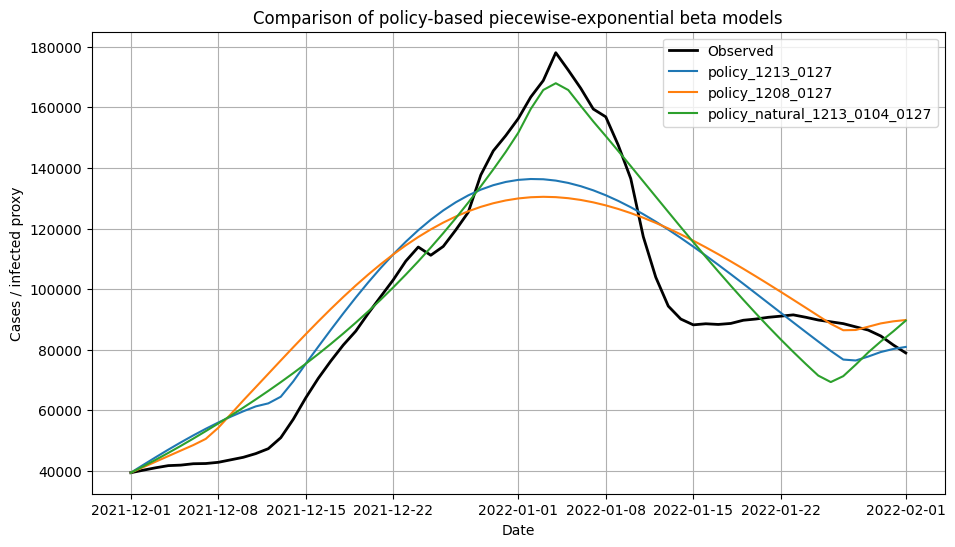

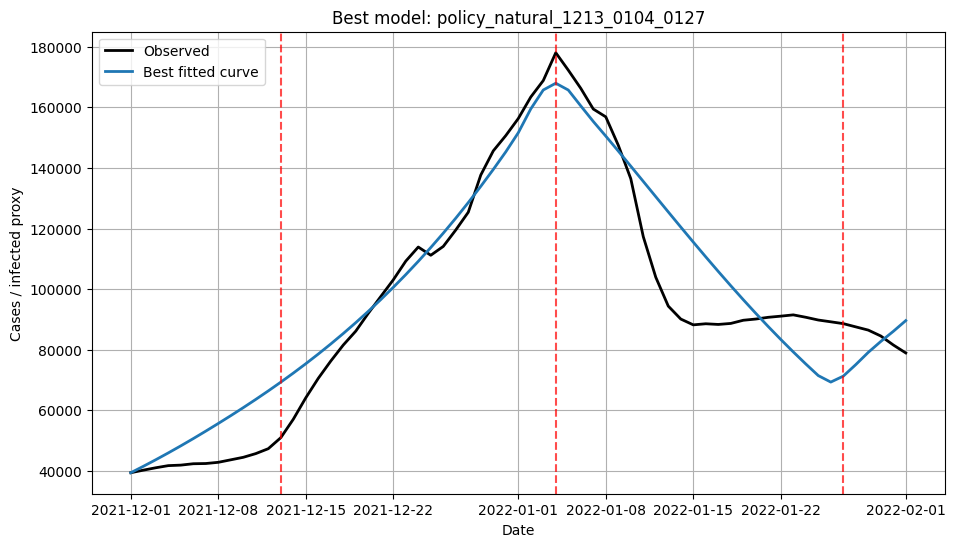

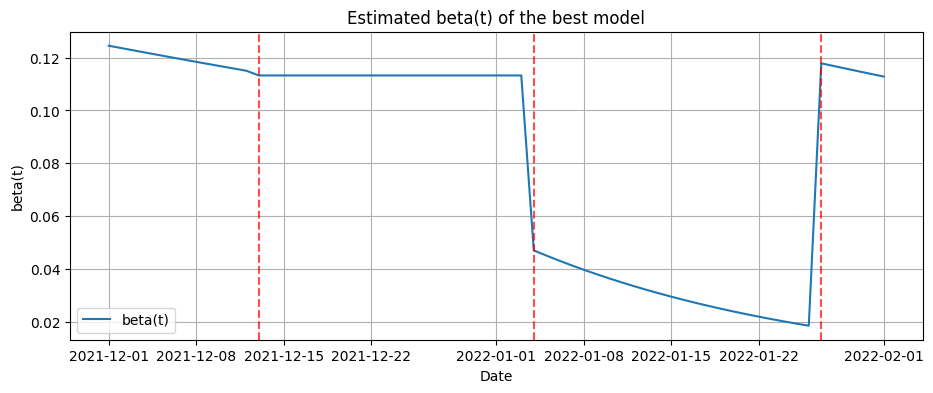

In [5]:
candidates = [
    {
        "model": "policy_1213_0127",
        "break_dates": ["2021-12-13", "2022-01-27"]
    },
    {
        "model": "policy_1208_0127",
        "break_dates": ["2021-12-08", "2022-01-27"]
    },
    {
        "model": "policy_natural_1213_0104_0127",
        "break_dates": ["2021-12-13", "2022-01-04", "2022-01-27"]
    }
]

results = []
for c in candidates:
    res = fit_model_for_break_dates(c["break_dates"], c["model"])
    results.append(res)

summary_rows = []
for res in results:
    row = {
        "model": res["model"],
        "break_dates": ", ".join(res["break_dates"]),
        "gamma": res["gamma"],
        "mse": res["mse"],
        "rmse": res["rmse"]
    }

    for i, b in enumerate(res["beta_base"], start=1):
        row[f"beta{i}"] = b
    for i, lam in enumerate(res["lambdas"], start=1):
        row[f"lambda{i}"] = lam

    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
summary = summary.sort_values("rmse").reset_index(drop=True)
print(summary)

best_model_name = summary.loc[0, "model"]
best_result = [r for r in results if r["model"] == best_model_name][0]

print("\nBest model:", best_result["model"])
print("Break dates:", best_result["break_dates"])
print("beta_base:", best_result["beta_base"])
print("lambdas:", best_result["lambdas"])
print("gamma:", best_result["gamma"])
print("RMSE:", best_result["rmse"])

# plot all fitted curves
plt.figure(figsize=(11, 6))
plt.plot(df_fit["date"], data, label="Observed", linewidth=2, color="black")

for res in results:
    plt.plot(df_fit["date"], res["I_fit"], label=res["model"])

plt.title("Comparison of policy-based piecewise-exponential beta models")
plt.xlabel("Date")
plt.ylabel("Cases / infected proxy")
plt.legend()
plt.grid()
plt.show()

# plot best model only
plt.figure(figsize=(11, 6))
plt.plot(df_fit["date"], data, label="Observed", linewidth=2, color="black")
plt.plot(df_fit["date"], best_result["I_fit"], label="Best fitted curve", linewidth=2)

for d in best_result["break_dates"]:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)

plt.title(f"Best model: {best_result['model']}")
plt.xlabel("Date")
plt.ylabel("Cases / infected proxy")
plt.legend()
plt.grid()
plt.show()

# beta path of best model
plt.figure(figsize=(11, 4))
plt.plot(df_fit["date"], best_result["beta_path"], label="beta(t)")
for d in best_result["break_dates"]:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Estimated beta(t) of the best model")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.show()